# 01 · The full pipeline on one page

One scanned page goes through all four stages, using the app's own code:

1. **Preprocessing**: clean the scan (the PORCONES recipe, notebook 02)
2. **Text detection**: one box per line (notebook 03)
3. **Text recognition**: read each line with the CRNN and with TrOCR (notebook 04)
4. **LLM post-processing**: correct the remaining errors with the fine-tuned Gemma (notebook 05)

The page is *PORCONES.23.5 (1628)*, a book that is not in any training data. Detection boxes are
cached by `scripts/evaluate.py detect`; delete the `.boxes.json` file to re-run detection.

In [1]:
# Make experimentation/src importable (this also puts backend/ on sys.path, so the
# notebooks run the app's own preprocessing, detection and recognition code).
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
%matplotlib inline

In [2]:
import cv2, matplotlib.pyplot as plt, numpy as np, torch
from src import figures
from src.evaluation import PageDetector, Recognizer, scores
from src.pages import build_test_pages
from src.paths import CHECKPOINTS

page = next(p for p in build_test_pages() if p.book.startswith("PORCONES") and p.name == "page1")
print(f"{page.book} / {page.name}: {len(page.lines)} lines, {len(page.text.split())} words in the transcription")

PORCONES.23.5 - 1628 / page1: 17 lines, 92 words in the transcription


## 1. Preprocessing

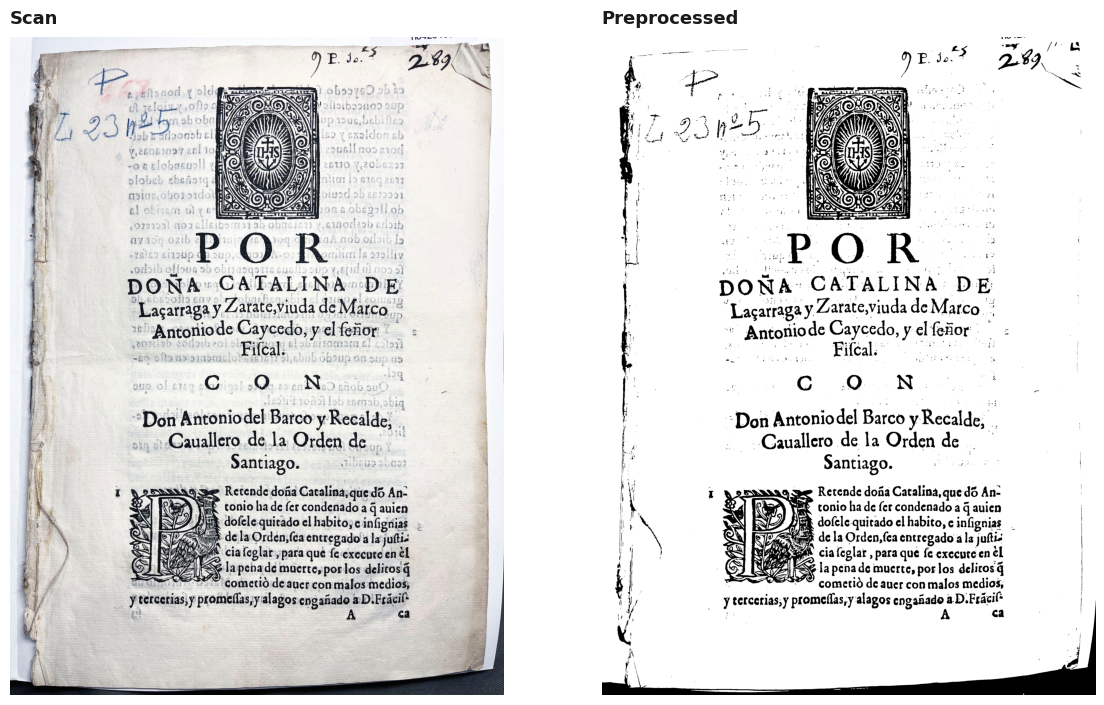

In [3]:
detector = PageDetector("cleaned")
image = detector.image(page)
fig, axes = plt.subplots(1, 2, figsize=(14, 9))
axes[0].imshow(figures.rgb(cv2.imread(str(page.image)))); axes[0].set_title("Scan")
axes[1].imshow(figures.rgb(image)); axes[1].set_title("Preprocessed")
for ax in axes: ax.axis("off")

## 2. Text detection

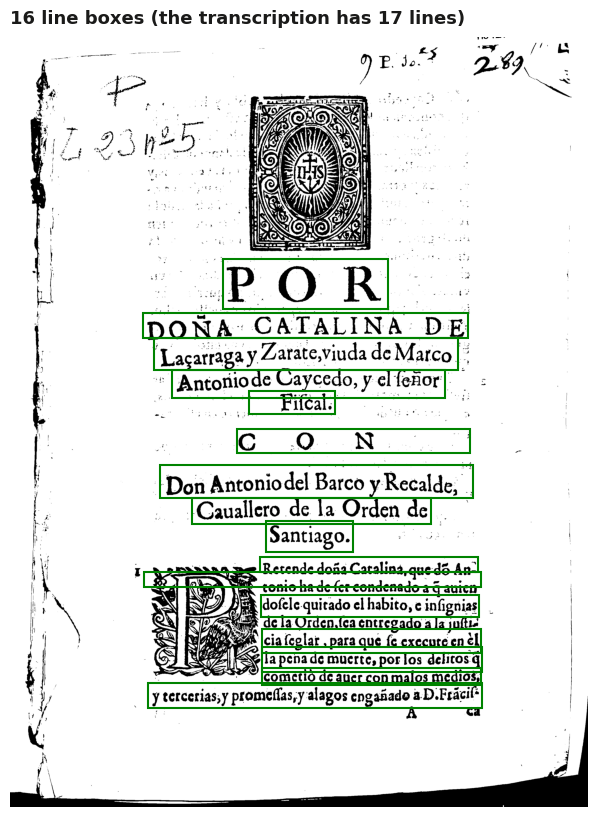

In [4]:
boxes = detector.boxes(page)
fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(figures.rgb(image)); figures.draw_polys(ax, [np.asarray(b) for b in boxes], figures.GREEN, 1.5)
ax.set_title(f"{len(boxes)} line boxes (the transcription has {len(page.lines)} lines)"); ax.axis("off");

## 3. Text recognition

In [5]:
models = {"CRNN": ("crnn", CHECKPOINTS / "crnn" / "best_crnn.pth"), "TrOCR": ("trocr", CHECKPOINTS / "trocr")}
read = {}
for name, (kind, path) in models.items():
    model = Recognizer(kind, path)
    read[name] = model.read_page(image, boxes)
    del model; torch.cuda.empty_cache()   # one model in GPU memory at a time
    s = scores([" ".join(read[name])], [page.text])
    print(f"{name:6s} page CER {s['cer']:.1%}  WER {s['wer']:.1%}")

The image processor of type `ViTImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


CRNN   page CER 20.0%  WER 31.5%


Loading weights:   0%|          | 0/480 [00:00<?, ?it/s]

TrOCR  page CER 20.0%  WER 33.7%


## 4. LLM post-processing (fine-tuned Gemma-3-4B, 4-bit, line by line)

In [6]:
from app.services.llm_processing.local_client import LocalCorrector

corrector = LocalCorrector("google/gemma-3-4b-it", str(CHECKPOINTS / "postprocess" / "gemma-3-4b-it-lora"))
for name in list(read):
    fixed, _ = corrector.correct_lines(read[name])
    before, after = scores([" ".join(read[name])], [page.text]), scores([" ".join(fixed)], [page.text])
    print(f"{name:6s} page CER {before['cer']:.1%} -> {after['cer']:.1%}   WER {before['wer']:.1%} -> {after['wer']:.1%}")
    read[name + " + Gemma"] = fixed

`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/883 [00:00<?, ?it/s]

/home/sarthak/miniconda3/envs/RenaissanceDetect/lib/python3.10/site-packages/peft/peft_model.py:622: UserWarning: Found missing adapter keys while loading the checkpoint: ['base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.k_proj.lora_A.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.k_proj.lora_B.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.v_proj.lora_A.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.v_proj.lora_B.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.q_proj.lora_A.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.0.self_attn.q_proj.lora_B.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.1.self_attn.k_proj.lora_A.default.weight', 'base_model.model.model.vision_tower.vision_model.encoder.layers.1.self_

CRNN   page CER 20.0% -> 20.7%   WER 31.5% -> 30.4%


TrOCR  page CER 20.0% -> 19.8%   WER 33.7% -> 31.5%


## Output

In [7]:
print("\n".join(read["TrOCR + Gemma"]))

POR
DONA CATALINA DE
Lazarra y Zarate, viuda de Marco
Antonio de Caycedo, y el señor
Fiscal.
CON
Don Antonio del Barco y Recalde,
Caballero de la Orden de
Santiago.
Perende doña Catalina que

dosele quitado el habito, e insignas
cia seglar, para que se execute en el
la pena de muerte, por los delitos que
cometio de aver con malos medios,
y tercerias, y promesas, y alagos engañado a D. Francis-
